# 01 – Veri Seti Seçimi ve Tanıtımı

Bu notebook veri setini yükler, yapısını ve hedef değişkeni tanıtır, problemli kayıtları tespit edip temizler ve temiz veri üzerinde keşifsel analiz grafiklerini üretir.
Temiz veri `data/phishing_temiz.csv`, grafikler `outputs/figures/` klasörüne kaydedilir.

## 1. Kurulum

In [1]:
# Paketler kurulu değilse bir kez çalıştırın
#%pip install pandas numpy matplotlib seaborn ucimlrepo

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Veri ve çıktı klasörleri (varsa dokunmaz)
os.makedirs("data", exist_ok=True)
os.makedirs("outputs/figures", exist_ok=True)

def grafik_kaydet(ad):
    # O anki grafiği rapor için PNG olarak kaydeder
    plt.savefig(f"outputs/figures/{ad}.png", dpi=150, bbox_inches="tight")

## 2. Veri setinin kaynağı ve amacı

**Veri seti:** [UCI Machine Learning Repository – Phishing Websites](https://archive.ics.uci.edu/dataset/327/phishing+websites) (Mohammad, McCluskey ve Thabtah, 2015)

**Kaynak:** Phishing siteleri PhishTank ve MillerSmiles arşivlerinden, normal siteler Google arama operatörleriyle toplanmıştır.

**Amaç:** Bir web sitesinin URL, HTML/JavaScript ve domain bilgilerinden çıkarılan özelliklere bakarak sitenin phishing olup olmadığını tahmin etmek (ikili sınıflandırma).

`data/phishing_raw.csv` varsa oradan okunur, yoksa UCI'dan indirilip bu dosyaya kaydedilir.

In [2]:
data = "data/phishing_raw.csv"

if os.path.exists(data):
    df = pd.read_csv(data)
else:
    from ucimlrepo import fetch_ucirepo
    phishing = fetch_ucirepo(id=327)
    df = pd.concat([phishing.data.features, phishing.data.targets], axis=1)
    df.to_csv(data, index=False)

hedef = df.columns[-1]                  # hedef değişken son sütun (result)
ozellikler = df.columns.drop(hedef)     # 30 özellik
etiket = {-1: "Phishing", 1: "Normal"}  # grafiklerde okunabilir sınıf adları

df.head()

,having_ip_address,url_length,shortining_service,having_at_symbol,double_slash_redirecting,prefix_suffix,having_sub_domain,sslfinal_state,domain_registration_length,favicon,...,popupwindow,iframe,age_of_domain,dnsrecord,web_traffic,page_rank,google_index,links_pointing_to_page,statistical_report,result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1


## 3. Veri setinin yapısı

Özelliklerin tamamı yazarlar tarafından kurallarla kodlanmış tamsayılardır: **-1** phishing belirtisi, **0** şüpheli, **1** normal. Bazı özellikler yalnızca -1 ve 1 değerlerini alır.

In [3]:
print("Satır sayısı  :", df.shape[0])
print("Özellik sayısı:", len(ozellikler))

Satır sayısı  : 11055
Özellik sayısı: 30


In [4]:
# Veri türleri ve boş olmayan değer sayıları
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11055 entries, 0 to 11054
Data columns (total 31 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   having_ip_address           11055 non-null  int64
 1   url_length                  11055 non-null  int64
 2   shortining_service          11055 non-null  int64
 3   having_at_symbol            11055 non-null  int64
 4   double_slash_redirecting    11055 non-null  int64
 5   prefix_suffix               11055 non-null  int64
 6   having_sub_domain           11055 non-null  int64
 7   sslfinal_state              11055 non-null  int64
 8   domain_registration_length  11055 non-null  int64
 9   favicon                     11055 non-null  int64
 10  port                        11055 non-null  int64
 11  https_token                 11055 non-null  int64
 12  request_url                 11055 non-null  int64
 13  url_of_anchor               11055 non-null  int64
 14  links_in_tags    

In [5]:
# Her sütunun kaç farklı değer aldığı (2 veya 3)
df.nunique()

having_ip_address             2
url_length                    3
shortining_service            2
having_at_symbol              2
double_slash_redirecting      2
prefix_suffix                 2
having_sub_domain             3
sslfinal_state                3
domain_registration_length    2
favicon                       2
port                          2
https_token                   2
request_url                   2
url_of_anchor                 3
links_in_tags                 3
sfh                           3
submitting_to_email           2
abnormal_url                  2
redirect                      2
on_mouseover                  2
rightclick                    2
popupwindow                   2
iframe                        2
age_of_domain                 2
dnsrecord                     2
web_traffic                   3
page_rank                     2
google_index                  2
links_pointing_to_page        3
statistical_report            2
result                        2
dtype: i

## 4. Hedef değişken

Hedef değişken **`result`** sütunudur: **-1 = Phishing**, **1 = Normal**.

In [6]:
print("Hedef değişken:", hedef)
print("Aldığı değerler:", sorted(df[hedef].unique().tolist()))

Hedef değişken: result
Aldığı değerler: [-1, 1]


### 4.1 Sınıf dağılımı (ham veri)

Bu grafik temizlik öncesine aittir. Temizlik sonrası dağılım 5. bölümün sonunda verilmiştir.

result
Phishing    4898
Normal      6157
Name: count, dtype: int64
result
Phishing    44.31
Normal      55.69
Name: count, dtype: float64
Dengesizlik oranı: 1.26


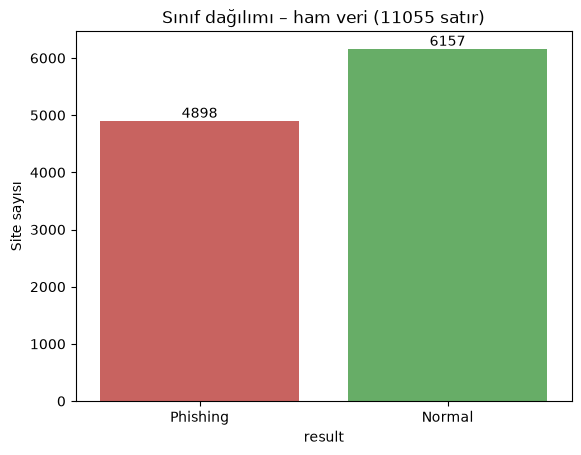

In [7]:
sinif = df[hedef].map(etiket).value_counts().reindex(["Phishing", "Normal"])
print(sinif)
print((sinif / len(df) * 100).round(2))
print("Dengesizlik oranı:", round(sinif.max() / sinif.min(), 2))

ax = sns.barplot(x=sinif.index, y=sinif.values, hue=sinif.index,
                 palette=["#d9534f", "#5cb85c"], legend=False)
for c in ax.containers:
    ax.bar_label(c)                     # çubukların üstüne adet yazar
plt.title(f"Sınıf dağılımı – ham veri ({len(df)} satır)")
plt.ylabel("Site sayısı")
grafik_kaydet("sinif_dagilimi_ham")
plt.show()

## 5. Anormal ve problemli veriler

Üç tür problem kontrol edilir:
- **Eksik değer:** bu veri setinde bulunmuyor.
- **Tekrarlanan satır:** birebir aynı kayıtlar. Silinmezse aynı satır hem train hem test kümesine düşebilir ve test başarısı olduğundan yüksek ölçülür.
- **Çelişkili kayıt:** 30 özelliği birebir aynı olduğu halde etiketi farklı olan kayıtlar. Model bu kayıtları ayırt edemez, etiket gürültüsü olarak kabul edilir.

In [8]:
print("Eksik değer:", df.isnull().sum().sum())
print("Tekrarlanan satır:", df.duplicated().sum())

celiskili = (df.groupby(list(ozellikler))[hedef].nunique() > 1).sum()
print("Çelişkili kayıt grubu:", celiskili)

Eksik değer: 0
Tekrarlanan satır: 5206
Çelişkili kayıt grubu: 64


### 5.1 Temizleme

- Eksik değer bulunmadığı için doldurma yapılmamıştır (eksik veri deneyi `02_on_isleme` notebook'unda yapılacaktır).
- Tekrarlanan satırlardan yalnızca biri bırakılmıştır.
- Çelişkili kayıtlar silinmiştir.

Bu işlemler veriden bir istatistik öğrenmediği için train/test ayrımından önce yapılmaları veri sızıntısına yol açmaz.

In [9]:
onceki = len(df)

# Tekrarlanan satırları sil, her kombinasyondan bir tane kalır
df = df.drop_duplicates().reset_index(drop=True)
print(f"Tekrar silindi: {onceki - len(df)} satır, kalan: {len(df)}")

# Çelişkili kayıtları sil (aynı özellik, farklı etiket)
celiskili_mi = df.groupby(list(ozellikler))[hedef].transform("nunique") > 1
df = df[~celiskili_mi].reset_index(drop=True)
print(f"Çelişkili silindi: {celiskili_mi.sum()} satır, kalan: {len(df)}")

print(f"Toplam silinen: {onceki - len(df)} (%{(onceki - len(df)) / onceki * 100:.1f})")

Tekrar silindi: 5206 satır, kalan: 5849
Çelişkili silindi: 128 satır, kalan: 5721
Toplam silinen: 5334 (%48.2)


In [10]:
# Temizlik sonrası sınıf dağılımı
sinif_temiz = df[hedef].map(etiket).value_counts().reindex(["Phishing", "Normal"])
print(pd.DataFrame({"ham": sinif, "temiz": sinif_temiz,
                    "temiz (%)": (sinif_temiz / len(df) * 100).round(2)}))
print("Dengesizlik oranı (temiz):", round(sinif_temiz.max() / sinif_temiz.min(), 2))

# 02_on_isleme buradan okuyacak
df.to_csv("data/phishing_temiz.csv", index=False)

           ham  temiz  temiz (%)
result                          
Phishing  4898   2955      51.65
Normal    6157   2766      48.35
Dengesizlik oranı (temiz): 1.07


## 6. Grafiksel analiz (temiz veri)

### 6.1 Özellik değerine göre phishing oranı

Her özelliğin her değeri için sitelerin yüzde kaçının phishing olduğu. Çubuklar arasındaki fark büyükse özellik ayırt edicidir.

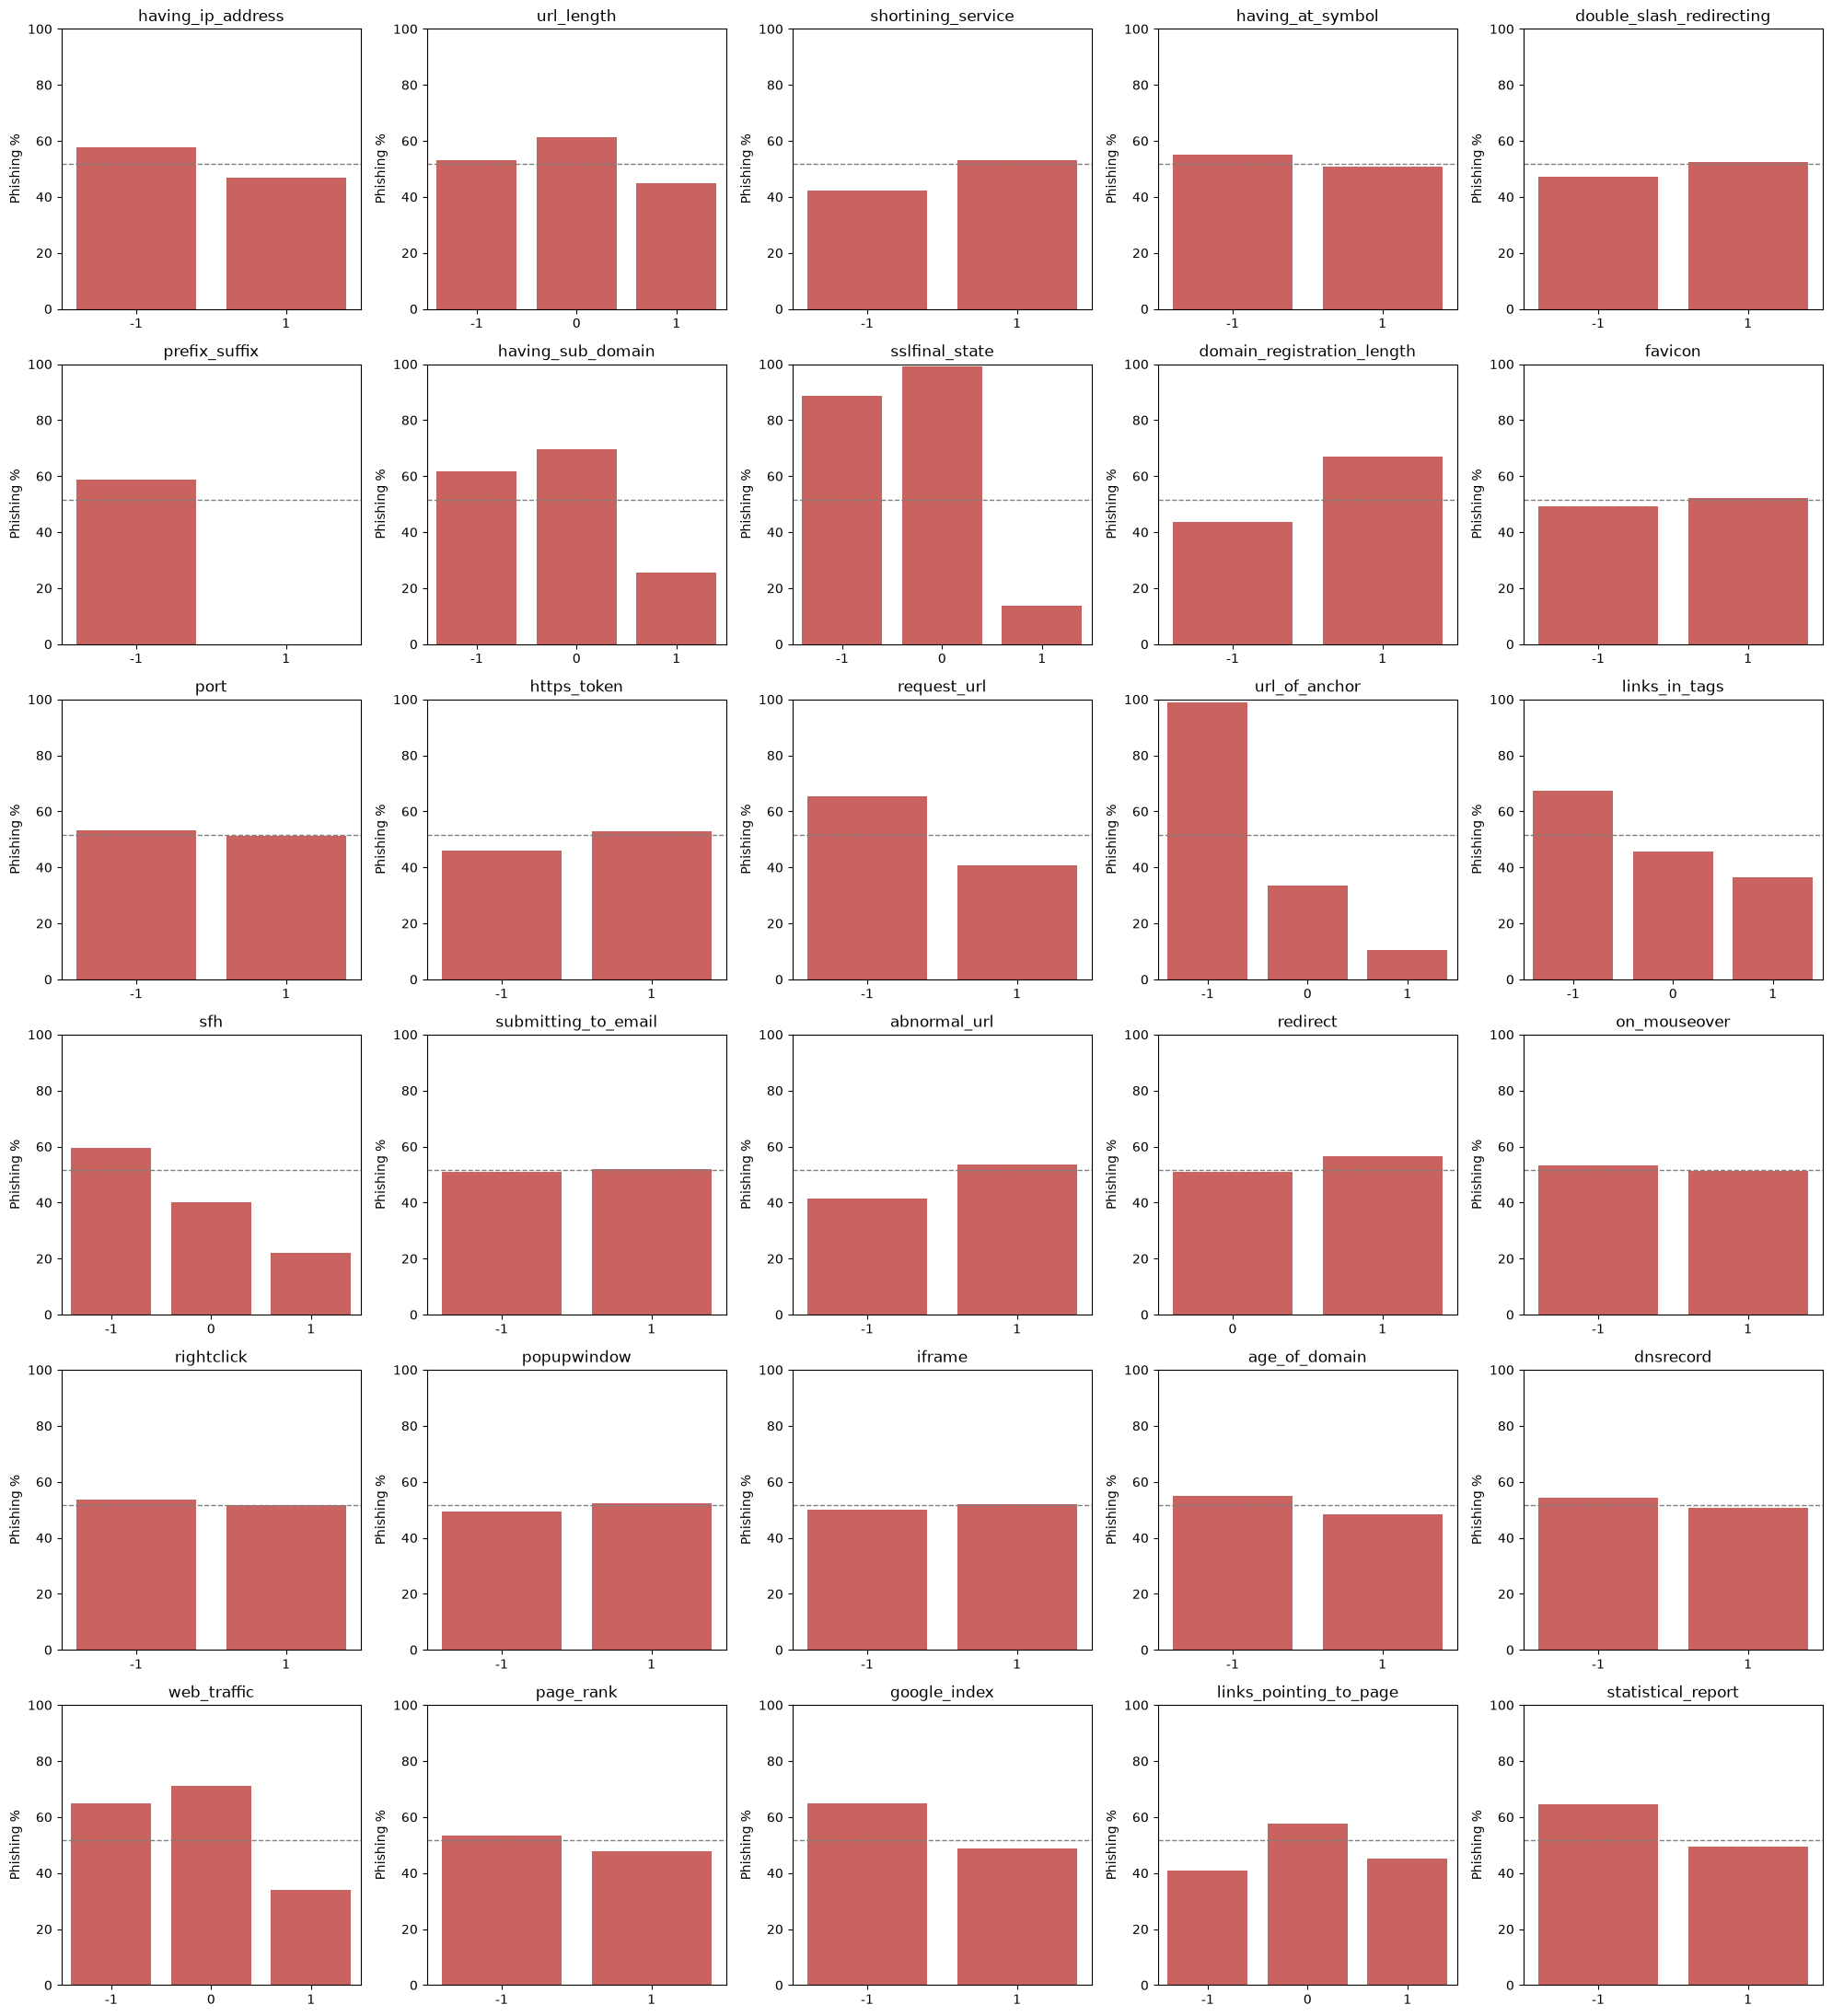

In [11]:
genel_oran = (df[hedef] == -1).mean() * 100

fig, axes = plt.subplots(6, 5, figsize=(20, 22))
for ax, col in zip(axes.flat, ozellikler):
    oran = df.groupby(col)[hedef].apply(lambda s: (s == -1).mean() * 100)
    sns.barplot(x=oran.index.astype(str), y=oran.values, ax=ax, color="#d9534f")
    ax.axhline(genel_oran, color="gray", linestyle="--", linewidth=1)  # genel phishing oranı
    ax.set_title(col)
    ax.set_ylim(0, 100)
    ax.set_xlabel("")
    ax.set_ylabel("Phishing %")
plt.tight_layout()
grafik_kaydet("degere_gore_phishing_orani")
plt.show()

### 6.2 Korelasyon ısı haritası

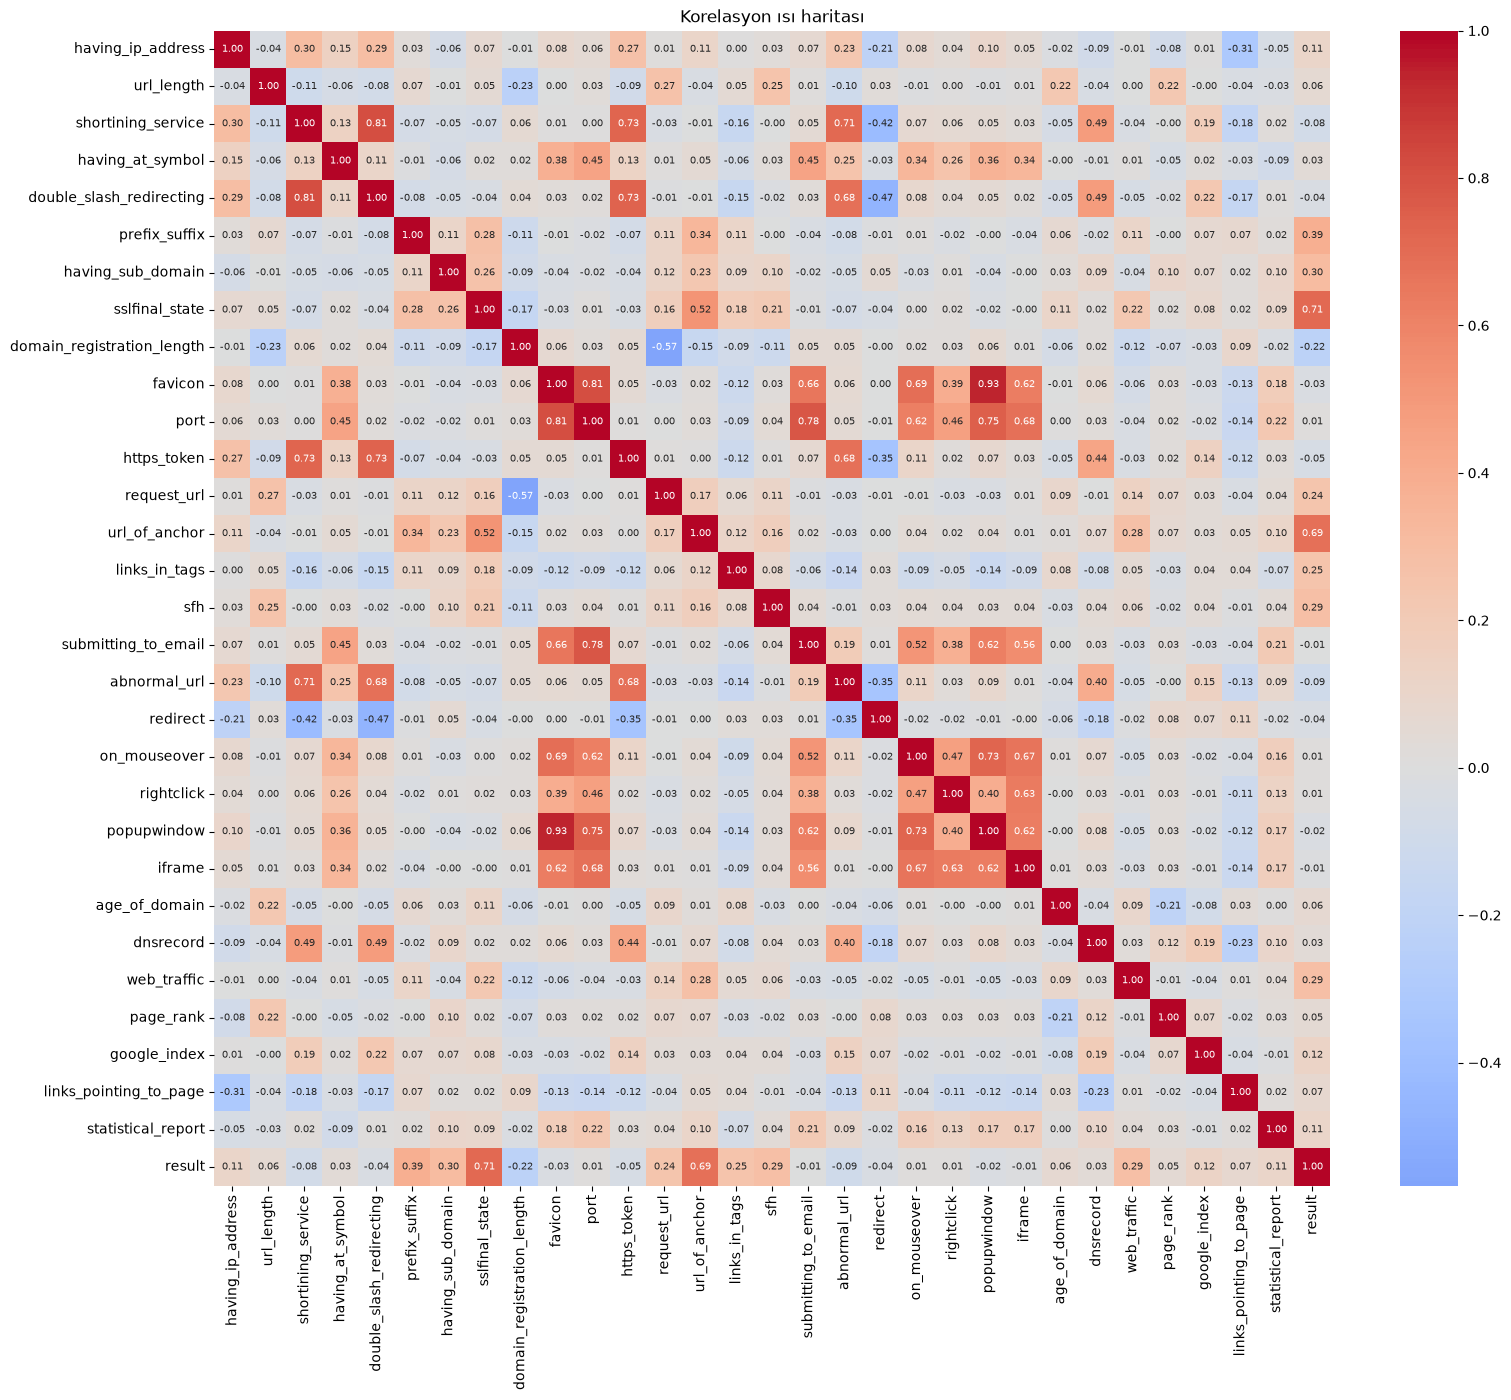

favicon                   popupwindow                 0.932738
shortining_service        double_slash_redirecting    0.814380
favicon                   port                        0.811760
port                      submitting_to_email         0.783812
                          popupwindow                 0.753743
double_slash_redirecting  https_token                 0.734734
on_mouseover              popupwindow                 0.730671
shortining_service        https_token                 0.727873
                          abnormal_url                0.709384
dtype: float64


In [13]:
korelasyon = df.corr()

plt.figure(figsize=(18, 15))
sns.heatmap(korelasyon, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Korelasyon ısı haritası")
grafik_kaydet("korelasyon")
plt.show()

# Korelasyonu |r| > 0.7 olan özellik çiftleri (hedef hariç).
# Bu çiftler büyük ölçüde aynı bilgiyi taşır; feature selection aşamasında (02) biri çıkarılabilir.
oz_kor = korelasyon.drop(index=hedef, columns=hedef)
ust = oz_kor.where(np.triu(np.ones(oz_kor.shape, dtype=bool), k=1))
print(ust.stack()[lambda s: s.abs() > 0.7].sort_values(ascending=False))

### 6.3 Özelliklerin hedefle korelasyonu

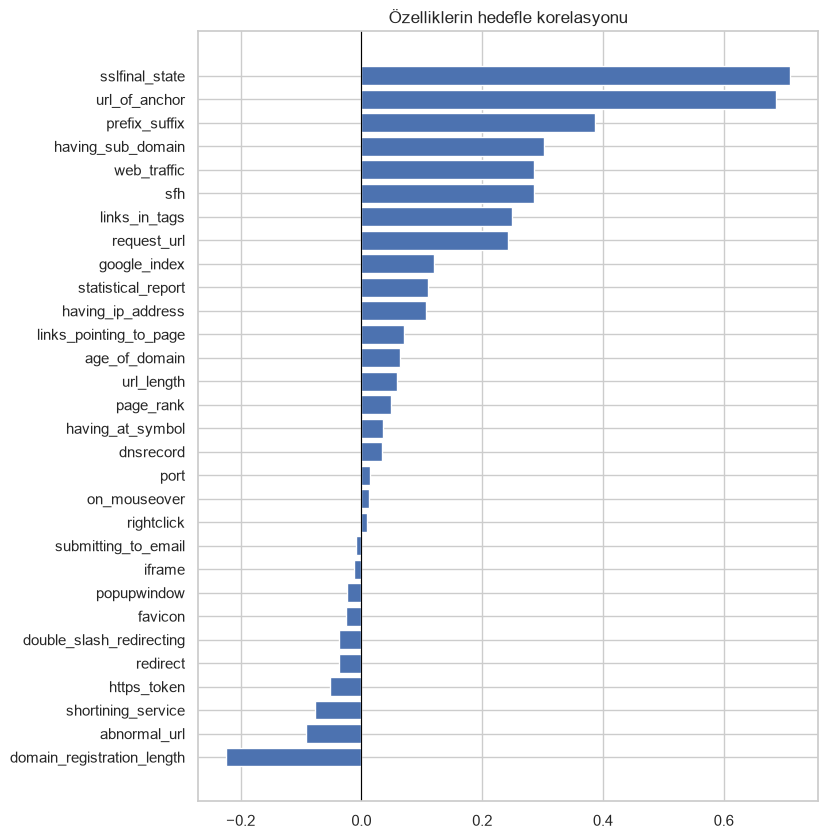

sslfinal_state                0.709765
url_of_anchor                 0.687107
prefix_suffix                 0.386242
having_sub_domain             0.302746
web_traffic                   0.286628
sfh                           0.286143
links_in_tags                 0.248927
request_url                   0.242663
domain_registration_length    0.223581
google_index                  0.119731
Name: result, dtype: float64

In [26]:
hedef_kor = korelasyon[hedef].drop(hedef).sort_values()

plt.figure(figsize=(8, 10))
plt.barh(hedef_kor.index, hedef_kor.values)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Özelliklerin hedefle korelasyonu")
grafik_kaydet("hedefle_korelasyon")
plt.show()

# Hedefle en güçlü ilişkili 10 özellik
hedef_kor.abs().sort_values(ascending=False).head(10)